# Stage information in each spatial encoding

`multicellular/SpatialFeatureContribution.ipynb` showed that the share of a spatial encoding the MuVI factors keep depends on how strongly its features correlate with each other and with the other feature classes. Sparse encodings such as the MISTy importances correlate little. That share says nothing about whether the kept information matters. This notebook asks a clinical question instead. Which encoding carries the most information about the pT stage of the tumour, first as input features and then after MuVI compresses it into 10 factors?

The prediction task follows `StageXGB.ipynb` and `ValidateXGB.ipynb`:
- the same cores, which are the tumour cores with a pT1 to pT4 annotation and more than 20 epithelial cells
- the same outer split, which holds out 20 percent of the cores for validation
- the same 4 inner folds, on which the hyperparameters are chosen
- XGBoost over the same grid of 50 numbers of trees and 4 depths, scored by the macro F1 over the four stages

The six encodings are the feature sets of `SpatialFeatureContribution.ipynb`.

| Feature set | Spatial features it keeps |
|---|---|
| MISTy, all features | The 100 MISTy importances of the published model |
| MISTy, juxtaview features | The 43 MISTy importances at contact range, 40 pixels |
| MISTy, own-type and cancer neighbours | The MISTy importances in which the neighbouring cell type is either the target cell type itself, which measures how clustered that cell type is, or cancer cells, which measures how close it sits to the epithelium |
| COZI enrichment | The COZI scores in `data/cozi_all_fovs.csv`, also analysed in `spatial/cozienrichment.ipynb`, instead of any MISTy importance |
| Squidpy enrichment | The squidpy neighbourhood enrichment z-scores instead of any MISTy importance |
| No spatial | None |

> **Warning.** The code that computed `data/cozi_all_fovs.csv` is not in the repository, as `SpatialFeatureContribution.ipynb` notes. Until it is added and rerun, the provenance of the COZI scores cannot be checked.

Two groups of models use them, and the figures show them in two panels:
- The composition plus encoding models get the cell type composition of `StageXGB.ipynb` plus one spatial encoding. Here No spatial means composition alone. It is the reference, and the difference to it is what the spatial encoding adds.
- The MuVI factor models get only the 10 factor scores of MuVI, refit within each split for each feature set on the training cores only. The factors fit without any spatial feature are the reference.

The two groups answer different questions, so each is compared only within itself. The factors also carry the metabolic, functional and morphological features, which the composition plus encoding models do not see.

The notebook runs in the `pam-keras3` environment of `StageXGB.ipynb`. That environment has no MuVI, so the script `stage_fold_factors.py` fits the factors in the `liana-squidpy` environment of `SpatialFeatureContribution.ipynb`, and the notebook reads its output.

## Setup

In [1]:
import os
import re
import subprocess
import warnings
import numpy as np
import pandas as pd
from plotnine import *
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

data_dir = "../../data/"
output_dir = data_dir + "spatial_features/"
figure_dir = "../../figures/spatial_features/"
encoding_dir = output_dir + "stage_encodings/"
fold_factor_dir = output_dir + "stage_fold_factors/"
grid_path = output_dir + "stage_grid_f1.csv"
os.makedirs(figure_dir, exist_ok=True)

squidpy_python = os.path.expanduser("~/miniforge3/envs/liana-squidpy/bin/python")
fold_factor_script = "stage_fold_factors.py"
n_workers = 14                  # MuVI fits side by side on the CPU
n_threads = 2                   # torch threads per MuVI fit
n_jobs = 28                     # XGBoost fits side by side on the CPU
seeds = [0, 1, 2, 3, 4]         # MuVI seeds per feature set and split, as in stage_fold_factors.py
stages = ["pT1", "pT2", "pT3", "pT4"]
estimator_range = np.arange(15, 511, 10)
depth_range = np.arange(3, 10, 2)

# Colours of SpatialFeatureContribution.ipynb
set_colors = {"MISTy, all features": "#08306b", "MISTy, juxtaview features": "#2171b5", "MISTy, own-type and cancer neighbours": "#6baed6",
              "COZI enrichment": "#7570b3", "Squidpy enrichment": "#1b9e77", "No spatial": "#d95f0e"}
feature_sets = list(set_colors)
groups = ["Composition plus encoding", "MuVI factors"]

def slug(label):
    return re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_")

## 1. Cores and splits
The code repeats the selection and the splits of `StageXGB.ipynb` step by step. The validation cores printed below should match the list in that notebook.

In [2]:
cell_table = pd.read_csv(data_dir + "cell_table_with_types_stage.csv", usecols=["fov", "consensus", "Stage"],
                         low_memory=False)

meta = cell_table.loc[cell_table.consensus == "Cancer_cell", ["Stage", "fov"]]
sparse_epi_fovs = meta.fov.value_counts()[meta.fov.value_counts() <= 20].index
meta = meta.loc[~meta.fov.isin(sparse_epi_fovs)]
epithelial_subset = meta["Stage"].isin(stages).values

fov_stage_table = meta.loc[epithelial_subset].drop_duplicates().reset_index(drop=True)
fov_inner, fov_val, _, _ = train_test_split(
    fov_stage_table["fov"], fov_stage_table["Stage"], test_size=0.2, random_state=0, stratify=fov_stage_table["Stage"])
meta["inner"] = meta["fov"].isin(fov_inner)
meta_per_fov = meta.loc[epithelial_subset].groupby("fov").first()
print(" ".join(fov_val.sort_values()))

A1a A1f A1h A2g A2i A2q A2r A3m A4e A4n A5a A5q A6b A6c A6g A6m A6p A6q A6r A7f A7p A8a A8m A9o A9q B1h B1k B2a B2b B2k B2o B3c B3g B4b B4g B4m B6i B6q B7c B7p B7r B8b B8d B8g B8i B8l B9c B9d B9h B9m B9n B9o C1i C1l C2a C2f C2k C3c C3h C4a C4g C4k C5a C5k C5l C6d C8a C8h D1i D1l D1m D2e D2k D4c D5b D5d D5h D5k D5l D6c D6k D7a D8d D8h


Each split gives every core one of two roles. The classifier and MuVI learn from the training cores, and the test cores are scored. The four inner folds split the 80 percent of cores outside the validation set. The last split trains on all of these cores and tests on the validation cores.

In [3]:
inner_cells = meta.loc[epithelial_subset & meta["inner"].values]
splits = meta_per_fov[["Stage"]].copy()
inner_splits = []
for k, (train, test) in enumerate(StratifiedGroupKFold(n_splits=4).split(
        inner_cells, inner_cells["Stage"], groups=inner_cells["fov"]), start=1):
    split = f"Fold {k}"
    train_fovs, test_fovs = inner_cells.iloc[train].fov.unique(), inner_cells.iloc[test].fov.unique()
    splits[split] = np.where(splits.index.isin(train_fovs), "train", np.where(splits.index.isin(test_fovs), "test", ""))
    assert splits.loc[splits[split] == "test", "Stage"].nunique() == 4
    inner_splits.append(split)
splits["Held out"] = np.where(meta_per_fov["inner"], "train", "test")
split_names = inner_splits + ["Held out"]
splits.to_csv(output_dir + "stage_splits.csv")

pd.concat({split: splits[splits[split] != ""].groupby(split)["Stage"].value_counts().unstack()
           for split in split_names}).rename_axis(["split", "role"])

Stage           pT1  pT2  pT3  pT4
split    role                     
Fold 1   test     3   17   44   19
         train   11   51  130   59
Fold 2   test     4   17   44   20
         train   10   51  130   58
Fold 3   test     4   17   43   20
         train   10   51  131   58
Fold 4   test     3   17   43   19
         train   11   51  131   59
Held out test     4   17   44   19
         train   14   68  174   78

## 2. Classifier and baseline
Every model below goes through the same function. `StageXGB.ipynb` runs XGBoost on the GPU. On tables this small the CPU is several times faster, so the grids here run on the CPU, one fit per core. The two devices build nearly the same trees, but not exactly the same. The check reruns the best composition model of `StageXGB.ipynb`. On the GPU it should give the logged score exactly, which confirms the splits. On the CPU it shows how much the device alone changes the score.

In [4]:
encoder = LabelEncoder().fit(stages)

def split_score(frame, split, estimators, depth, device="cpu"):
    '''Macro F1 on the test cores of one split, for a classifier trained on its training cores'''
    train = splits.index[splits[split] == "train"]
    test = splits.index[splits[split] == "test"]
    xgb = XGBClassifier(n_estimators=int(estimators), max_depth=int(depth), device=device, random_state=0,
                        n_jobs=1 if device == "cpu" else None)
    with warnings.catch_warnings(action="ignore"):
        xgb.fit(frame.loc[train], encoder.transform(splits.loc[train, "Stage"]))
        predicted = xgb.predict(frame.loc[test])
    return f1_score(encoder.transform(splits.loc[test, "Stage"]), predicted, average="macro")

# Model 1 of StageXGB.ipynb: the fraction of each annotated cell type among all cells of the core
composition = pd.crosstab(cell_table.fov, cell_table.consensus, normalize="index").loc[splits.index]

logged = (pd.read_csv(data_dir + "model1_cell_composition_f1_scores.txt", header=None,
                      names=["estimators", "depth", "score"])
          .sort_values("score", ascending=False).iloc[0])
rerun = {device: np.median([split_score(composition, split, logged.estimators, logged.depth, device=device)
                            for split in inner_splits]) for device in ["cuda", "cpu"]}
assert np.isclose(rerun["cuda"], logged.score), "the splits differ from StageXGB.ipynb"
pd.DataFrame({"StageXGB.ipynb": logged.score, "rerun on the GPU": rerun["cuda"], "rerun on the CPU": rerun["cpu"]},
             index=[f"composition, {int(logged.estimators)} trees of depth {int(logged.depth)}"]).round(4)

,StageXGB.ipynb,rerun on the GPU,rerun on the CPU
"composition, 15 trees of depth 5",0.295,0.295,0.2729


As in `StageXGB.ipynb`, the baseline draws the predicted stages at random from the stages of the training cores, 1000 times per split. A model that learned nothing about the cores scores around the median of these draws.

In [5]:
rng = np.random.default_rng(0)
baseline = {}
for split in split_names:
    y_train = splits.loc[splits[split] == "train", "Stage"].values
    y_test = splits.loc[splits[split] == "test", "Stage"].values
    baseline[split] = [f1_score(y_test, rng.choice(y_train, len(y_test)), average="macro") for _ in range(1000)]
inner_baseline = np.median([baseline[split] for split in inner_splits])
held_out_baseline = np.median(baseline["Held out"])
pd.DataFrame({split: {"median": np.median(draws), "2.5th percentile": np.percentile(draws, 2.5),
                      "97.5th percentile": np.percentile(draws, 97.5)}
              for split, draws in baseline.items()}).T.round(3)

,median,2.5th percentile,97.5th percentile
Fold 1,0.244,0.166,0.347
Fold 2,0.240,0.165,0.350
Fold 3,0.242,0.163,0.351
Fold 4,0.248,0.164,0.348
Held out,0.244,0.166,0.351


## 3. Inputs
### Composition plus encoding
`stage_fold_factors.py export` writes the spatial block of each feature set exactly as MuVI receives it in `SpatialFeatureContribution.ipynb`. The feature names give the view, which is the cell type a feature describes, then the feature. A missing value marks a cell type absent from the core, or an enrichment score that is infinite because of it. XGBoost handles missing values directly.

In [6]:
if not os.path.isdir(encoding_dir):
    subprocess.run([squidpy_python, fold_factor_script, "export"], check=True, capture_output=True)
encodings = {label: pd.read_csv(encoding_dir + slug(label) + ".csv", index_col="fov").loc[splits.index]
             for label in feature_sets if label != "No spatial"}
assert not any(np.isinf(frame.values).any() for frame in encodings.values())
combined = {label: composition if label == "No spatial" else pd.concat([composition, encodings[label]], axis=1)
            for label in feature_sets}
pd.DataFrame({label: {"composition features": composition.shape[1],
                      "spatial features": frame.shape[1] - composition.shape[1],
                      "missing spatial values": int(frame.iloc[:, composition.shape[1]:].isna().sum().sum())}
              for label, frame in combined.items()}).T

,composition features,spatial features,missing spatial values
"MISTy, all features",15,100,0
"MISTy, juxtaview features",15,43,0
"MISTy, own-type and cancer neighbours",15,31,0
COZI enrichment,15,64,1
Squidpy enrichment,15,64,1259
No spatial,15,0,0


### MuVI factors within each split
For every feature set, split and seed, `stage_fold_factors.py fit` fits MuVI with the settings of the retained model, 10 factors without non-negativity, on the training cores of the split. Each feature is centred and scaled with the training cores only. The MuVI package has no function to score new cores, but the fit holds everything needed. MuVI models each scaled feature as the factor scores times the loadings, plus Gaussian noise with a variance per feature, and gives the factor scores a standard normal prior. The score of a test core is therefore the posterior mean of its factors given its features. It amounts to a least-squares fit of the core's features onto the loadings, weighted by the noise of each feature and pulled slightly towards zero by the prior, using only the features measured in that core. The training cores get their scores in the same way, so training and test cores sit on the same scale. The script checks that these scores match the ones MuVI fit for the training cores.

Five seeds per feature set and split show how much the stage prediction moves when only the seed changes. The 150 fits run once and are cached. They run on the CPU, 14 at a time. The model is small, so on the GPU most of the time goes to launching kernels, and separate processes cannot share the GPU efficiently. The device changes the numbers of a fit slightly, so these factors are not bit-identical to GPU fits with the same seed. Nothing here needs them to be, since every fit is new.

In [7]:
os.makedirs(fold_factor_dir, exist_ok=True)
expected = [fold_factor_dir + f"{slug(label)}__{slug(split)}__seed{seed}.csv"
            for label in feature_sets for split in split_names for seed in seeds]
if not all(os.path.exists(path) for path in expected):
    workers = [subprocess.Popen([squidpy_python, fold_factor_script, "fit", "--worker", str(i), "--workers", str(n_workers),
                                 "--threads", str(n_threads)],
                                stdout=open(fold_factor_dir + f"worker{i}.log", "w"), stderr=subprocess.STDOUT)
               for i in range(n_workers)]
    assert all(worker.wait() == 0 for worker in workers), "a MuVI worker failed, see its log"
fold_factors = pd.concat([pd.read_csv(path) for path in expected], ignore_index=True)
factor_order = [f"Factor {i}" for i in range(1, 11)]

(fold_factors.groupby(["feature set", "split", "seed"])["projection check"].first()
 .groupby("feature set").min().loc[feature_sets]
 .rename("lowest correlation of fitted and projected training scores").round(4).to_frame())

,lowest correlation of fitted and projected training scores
feature set,
"MISTy, all features",0.9972
"MISTy, juxtaview features",0.9951
"MISTy, own-type and cancer neighbours",0.9951
COZI enrichment,0.9968
Squidpy enrichment,0.9975
No spatial,0.9957


## 4. Grid search on the inner folds
Each model goes through the grid of `StageXGB.ipynb`. A setting scores the median macro F1 over the 4 inner folds, and the best setting is kept. Ties go to fewer trees, then to lower depth. The grid picks the setting on the same folds that score it, so the inner-fold scores are optimistic. The bias is the same for every model, and section 7 scores the held-out cores, which the grid never saw.

In [8]:
models = [{"group": groups[0], "feature set": label, "seed": np.nan, "frames": {split: frame for split in split_names}}
          for label, frame in combined.items()]
for label in feature_sets:
    for seed in seeds:
        subset = fold_factors[(fold_factors["feature set"] == label) & (fold_factors.seed == seed)]
        models.append({"group": groups[1], "feature set": label, "seed": seed,
                       "frames": {split: frame.set_index("fov")[factor_order] for split, frame in subset.groupby("split")}})
key = ["group", "feature set", "seed"]

def grid_row(index, estimators, depth):
    model = models[index]
    scores = [split_score(model["frames"][split], split, estimators, depth) for split in inner_splits]
    return {"model": index, **{k: model[k] for k in key}, "estimators": estimators, "depth": depth,
            **dict(zip(inner_splits, scores)), "median": np.median(scores)}

if os.path.exists(grid_path):
    grid = pd.read_csv(grid_path)
else:
    grid = pd.DataFrame([row for index in range(len(models)) for row in Parallel(n_jobs=n_jobs)(
        delayed(grid_row)(index, estimators, depth) for estimators in estimator_range for depth in depth_range)])
    grid.to_csv(grid_path, index=False)
assert len(grid) == len(models) * len(estimator_range) * len(depth_range)

best = (grid.sort_values(["median", "estimators", "depth"], ascending=[False, True, True])
        .groupby(key, dropna=False, sort=False).head(1).reset_index(drop=True))
best[best.group == groups[0]][["feature set", "estimators", "depth", "median"]].round(3)

,feature set,estimators,depth,median
2,"MISTy, own-type and cancer neighbours",75,9,0.327
8,"MISTy, juxtaview features",55,9,0.314
12,"MISTy, all features",25,9,0.304
15,No spatial,315,3,0.299
20,COZI enrichment,65,3,0.288
25,Squidpy enrichment,265,5,0.278


## 5. Stage prediction on the inner folds
Each point is one inner fold. For the factors, each fold appears once per seed, so 4 folds by 5 seeds. The crossbar marks the median, and the red dashed line the median of the resampled baseline.

group,Composition plus encoding,MuVI factors
feature set,,
"MISTy, all features",0.304,0.278
"MISTy, juxtaview features",0.314,0.287
"MISTy, own-type and cancer neighbours",0.327,0.296
COZI enrichment,0.288,0.291
Squidpy enrichment,0.278,0.294
No spatial,0.299,0.296


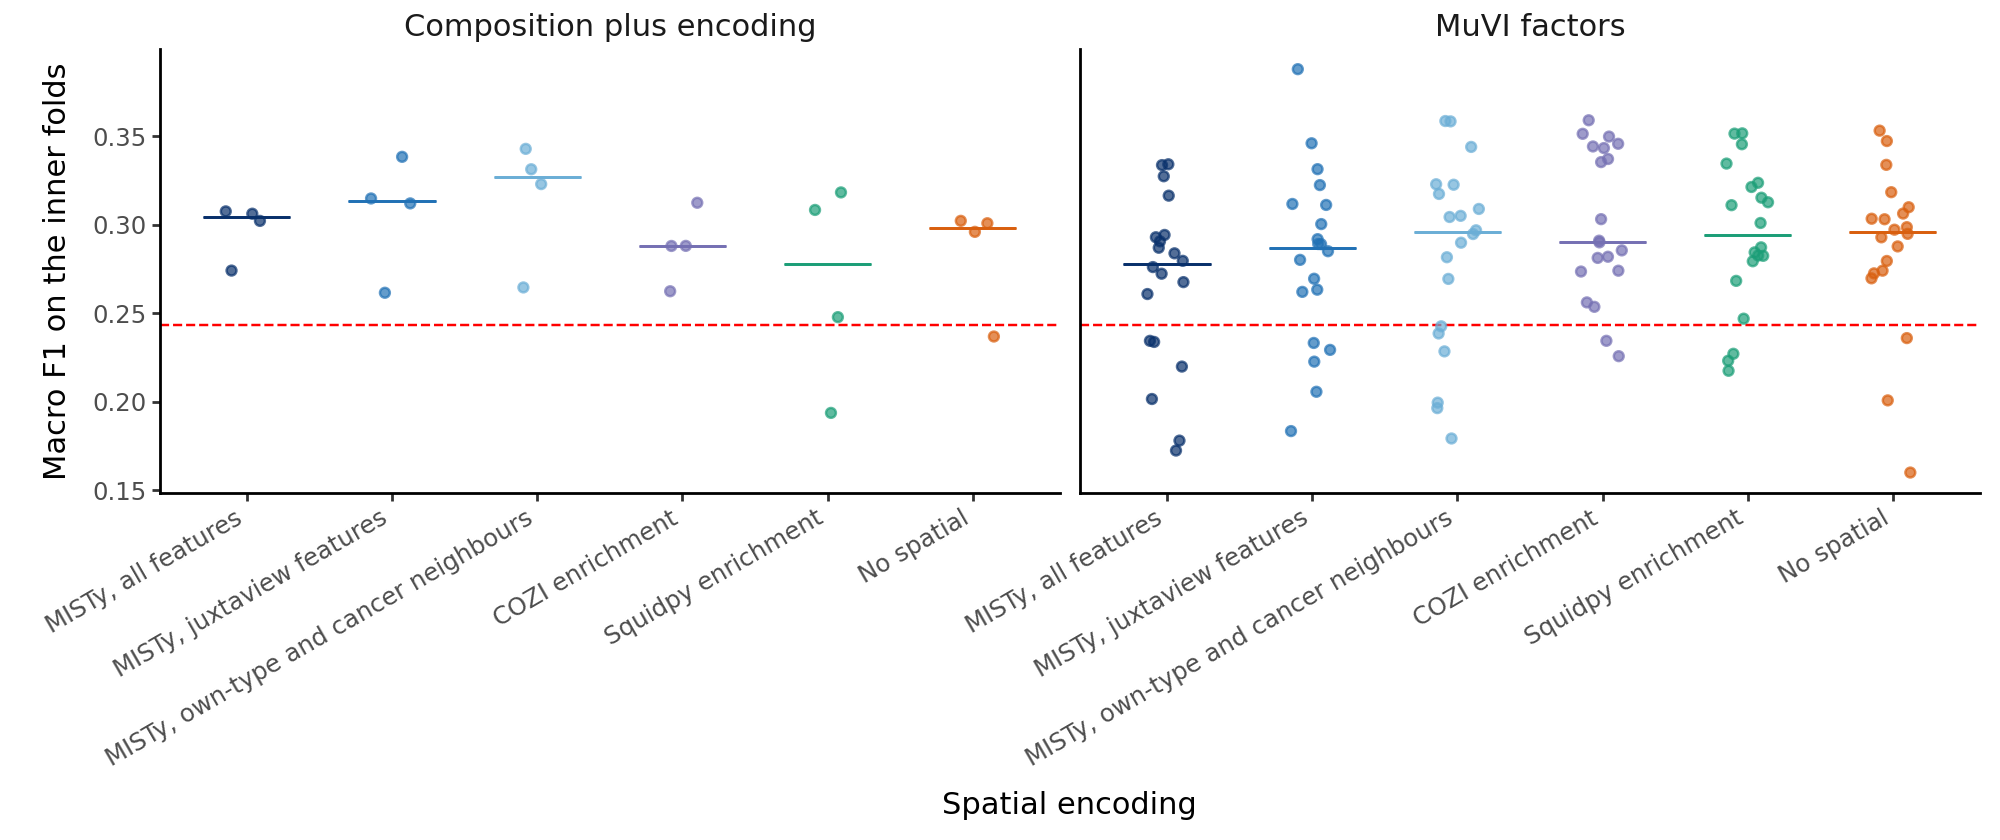

In [9]:
inner = best.melt(id_vars=key + ["estimators", "depth"], value_vars=inner_splits, var_name="fold", value_name="macro F1")
inner["feature set"] = pd.Categorical(inner["feature set"], categories=feature_sets)
inner["group"] = pd.Categorical(inner["group"], categories=groups)

def score_plot(frame, y, ylab, line):
    # The baseline as a red dashed line, or a black line at 0 for differences
    reference_line = (geom_hline(yintercept=0, color="black", size=0.3) if line == 0
                      else geom_hline(yintercept=line, linetype="dashed", color="red"))
    return (ggplot(frame, aes(x="feature set", y=y, color="feature set"))
            + reference_line
            + geom_point(position=position_jitter(width=0.15, height=0, random_state=0), size=1.5, alpha=0.7)
            + stat_summary(fun_y=np.median, fun_ymin=np.median, fun_ymax=np.median, geom="crossbar", width=0.6, size=0.3)
            + facet_wrap("~group", scales="free_x")
            + scale_color_manual(values=set_colors, guide=None)
            + labs(x="Spatial encoding", y=ylab)
            + theme_classic()
            + theme(figure_size=(10, 4.2), axis_text_x=element_text(rotation=30, ha="right"),
                    strip_background=element_blank(), strip_text=element_text(size=11)))

gp = score_plot(inner, "macro F1", "Macro F1 on the inner folds", inner_baseline)
gp.save(figure_dir + "stage_f1_inner_folds.pdf", verbose=False)
display(inner.groupby(["group", "feature set"], observed=True)["macro F1"].median().unstack("group").round(3))
gp

Every model scores above the median of the baseline, but most fold scores stay inside the range of the resampled draws. Pathological stage is hard to read from a single core, whatever the features. The pT stage measures how deep the whole tumour invades, and one core samples only a small part of it.

With composition, adding a MISTy encoding raises the median slightly. The MISTy importances of own-type and cancer neighbours do best. COZI leaves the score close to composition alone, and squidpy lowers it. The four folds spread more than these medians differ. The MuVI factors of the six feature sets reach nearly the same median, and the seeds spread each of them widely.

## 6. What the spatial information adds
Every model meets the same test cores in a given fold, so the comparison to the reference pairs the scores fold by fold. ΔMacro F1 is the macro F1 of a model minus that of its reference in the same fold. For the composition plus encoding models, the reference is composition alone, which therefore has no points of its own. For the MuVI factors, the reference is the median over the five seeds of the factors fit without any spatial feature. The points of that reference model then show how far its own seeds spread around their median, which is the scale a difference has to exceed. The crossbar marks the median, and the black line no difference.

median  \
group                     feature set                                     
Composition plus encoding MISTy, all features                     0.003   
                          MISTy, juxtaview features               0.014   
                          MISTy, own-type and cancer neighbours   0.026   
                          COZI enrichment                         0.002   
                          Squidpy enrichment                     -0.015   
MuVI factors              MISTy, all features                    -0.016   
                          MISTy, juxtaview features              -0.011   
                          MISTy, own-type and cancer neighbours   0.003   
                          COZI enrichment                        -0.005   
                          Squidpy enrichment                      0.003   
                          No spatial                              0.000   

                                                                   min    max  \
group                     feature set                                           
Composition plus encoding MISTy, all features                   -0.022  0.071   
                          MISTy, juxtaview features             -0.039  0.102   
                          MISTy, own-type and cancer neighbours -0.031  0.106   
                          COZI enrichment                       -0.014  0.026   
                          Squidpy enrichment                    -0.108  0.071   
MuVI factors              MISTy, all features                   -0.117  0.036   
                          MISTy, juxtaview features             -0.111  0.091   
                          MISTy, own-type and cancer neighbours -0.116  0.061   
                          COZI enrichment                       -0.069  0.071   
                          Squidpy enrichment                    -0.080  0.054   
                          No spatial                            -0.135  0.055   

                                                                 share_above_the_reference  
group                     feature set                                                       
Composition plus encoding MISTy, all features                                         0.75  
                          MISTy, juxtaview features                                   0.75  
                          MISTy, own-type and cancer neighbours                       0.75  
                          COZI enrichment                                             0.50  
                          Squidpy enrichment                                          0.50  
MuVI factors              MISTy, all features                                         0.25  
                          MISTy, juxtaview features                                   0.40  
                          MISTy, own-type and cancer neighbours                       0.50  
                          COZI enrichment                                             0.45  
                          Squidpy enrichment                                          0.50  
                          No spatial                                                  0.40

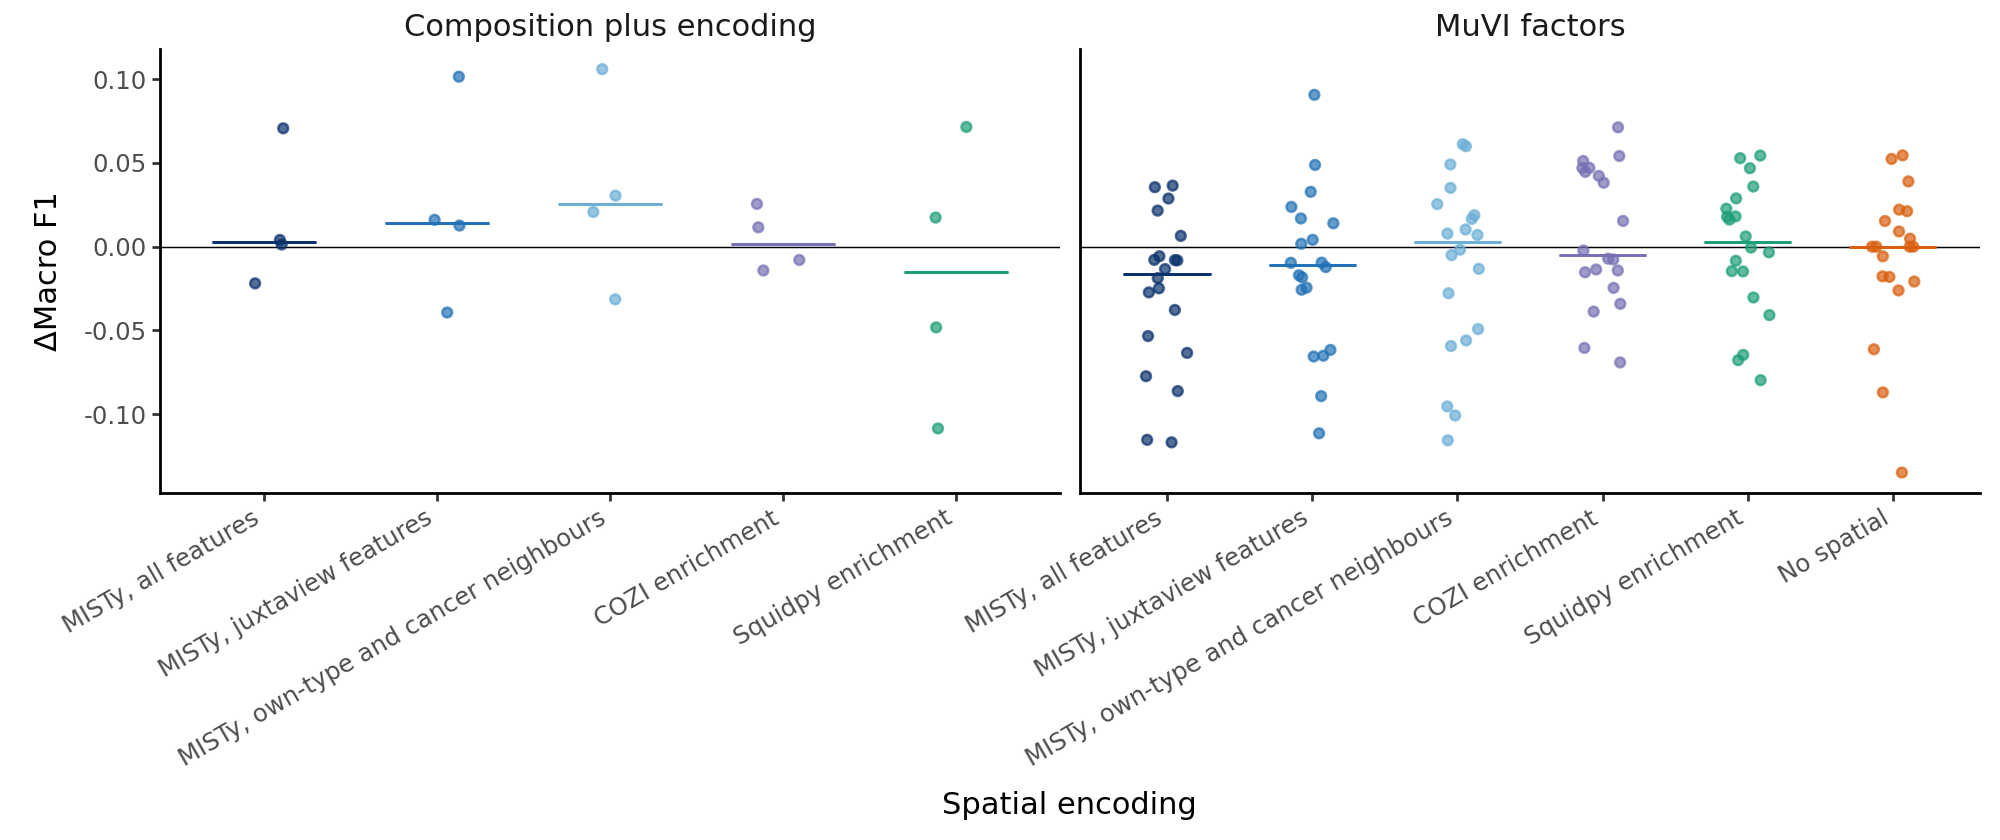

In [10]:
reference = inner[inner["feature set"] == "No spatial"].groupby(["group", "fold"], observed=True)["macro F1"].median()
inner["difference"] = inner["macro F1"].values - reference.loc[list(zip(inner.group, inner.fold))].values
difference = inner[~((inner.group == groups[0]) & (inner["feature set"] == "No spatial"))]

gp = score_plot(difference, "difference", "ΔMacro F1", 0)
gp.save(figure_dir + "stage_f1_difference_to_no_spatial.pdf", verbose=False)
display(difference.groupby(["group", "feature set"], observed=True)["difference"]
        .agg(median="median", min="min", max="max", share_above_the_reference=lambda d: (d > 0).mean()).round(3))
gp

Each MISTy encoding added to composition beats composition alone in three of the four folds by a small margin, and loses in the fourth. COZI and squidpy beat it in half of the folds. With four folds, none of these differences is consistent enough to count as added stage information. Section 2 gives a sense of scale. Running the same composition model on the CPU instead of the GPU changes its score by about as much as the medians here differ.

For the MuVI factors, the model without spatial features already spreads widely when only the seed changes, and no encoding moves the factors outside that spread. The encodings that MuVI compresses well do not give factors that predict stage better than factors without any spatial feature, and neither do the MISTy importances.

## 7. Held-out cores
As in `ValidateXGB.ipynb`, each model is trained on all cores outside the validation set with its best setting from the grid, then scored once on the validation cores. For the factors, MuVI was fit on the same training cores and the validation cores were projected onto its factors. The validation set holds few cores per stage, so a single score moves a lot when a few cores change class. In the figure, each composition plus encoding model gives one point, and the factors give one point per MuVI seed. The crossbar marks the median, and the red dashed line the median of the resampled baseline.

group,Composition plus encoding,MuVI factors
feature set,,
"MISTy, all features",0.333,0.282
"MISTy, juxtaview features",0.286,0.269
"MISTy, own-type and cancer neighbours",0.257,0.252
COZI enrichment,0.287,0.245
Squidpy enrichment,0.226,0.223
No spatial,0.162,0.224


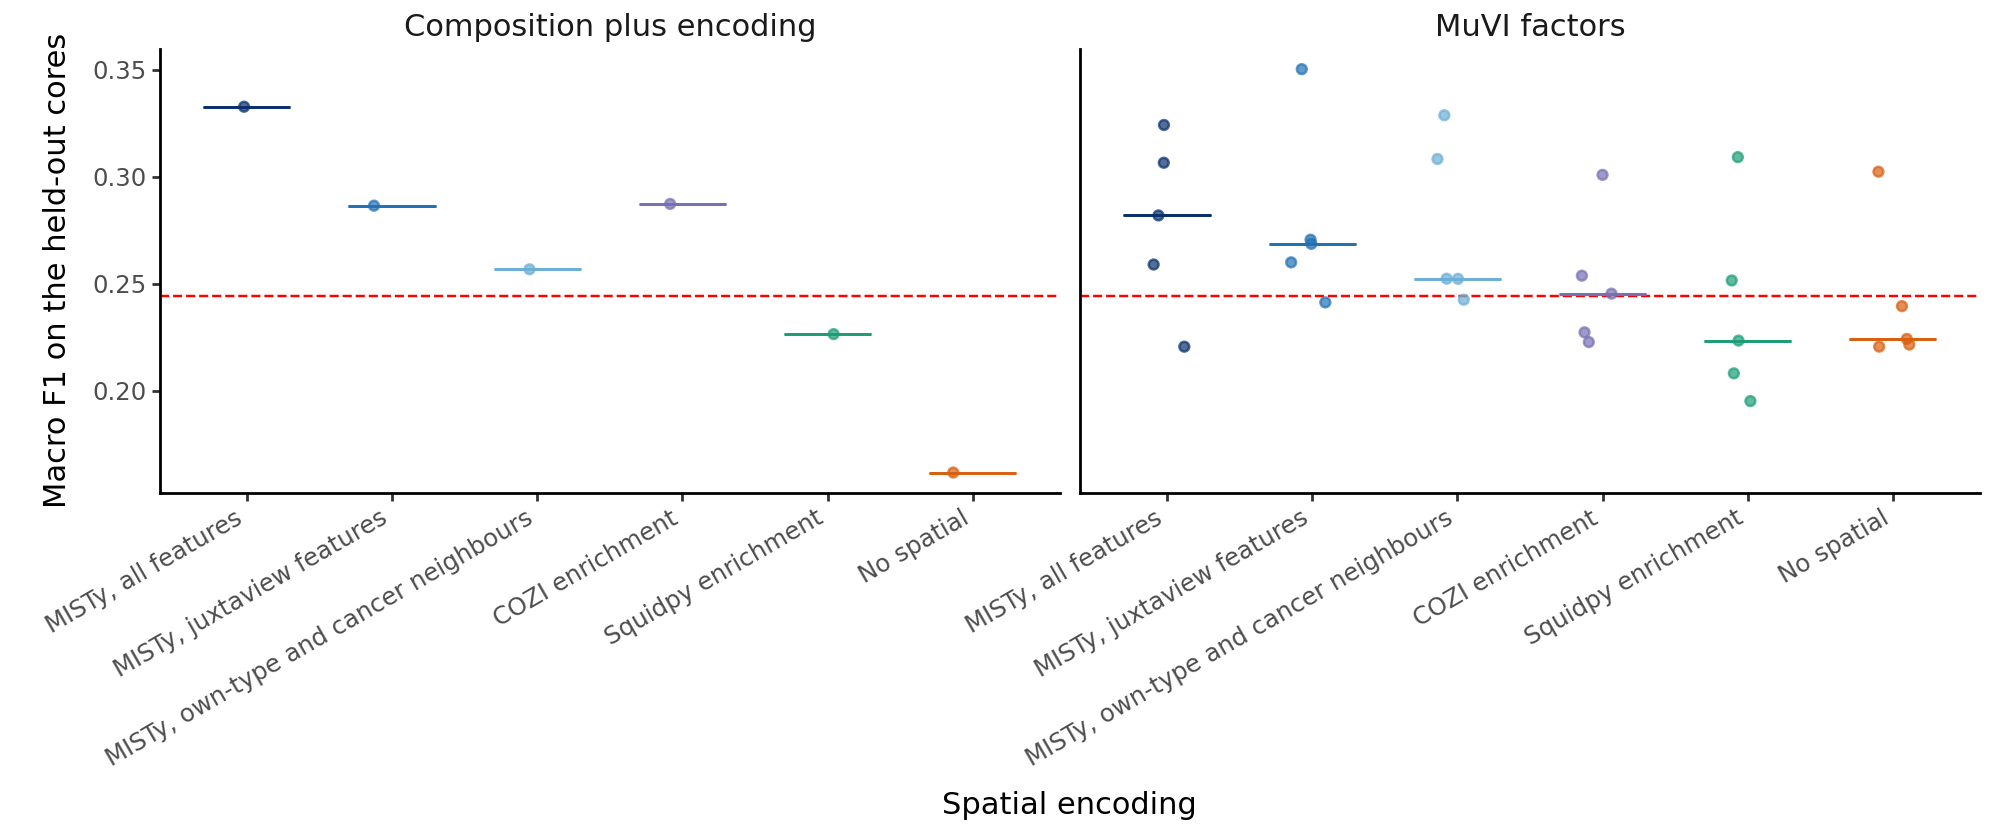

In [11]:
best["held-out macro F1"] = [split_score(models[row.model]["frames"]["Held out"], "Held out", row.estimators, row.depth)
                             for row in best.itertuples()]
held_out = best.copy()
held_out["feature set"] = pd.Categorical(held_out["feature set"], categories=feature_sets)
held_out["group"] = pd.Categorical(held_out["group"], categories=groups)

gp = score_plot(held_out, "held-out macro F1", "Macro F1 on the held-out cores", held_out_baseline)
gp.save(figure_dir + "stage_f1_held_out.pdf", verbose=False)
display(held_out.groupby(["group", "feature set"], observed=True)["held-out macro F1"].median()
        .unstack("group").round(3))
gp

Composition alone sits below the baseline here. The setting the grid chose on the CPU matters for this single score. The table puts it next to the setting of `StageXGB.ipynb` on both devices.

In [12]:
settings = best.loc[(best.group == groups[0]) & (best["feature set"] == "No spatial"), ["estimators", "depth"]].iloc[0]
pd.DataFrame({f"{int(estimators)} trees of depth {int(depth)}, {device}":
              {"held-out macro F1": split_score(composition, "Held out", estimators, depth, device=device)}
              for estimators, depth, device in [(settings.estimators, settings.depth, "cpu"),
                                                (logged.estimators, logged.depth, "cuda"),
                                                (logged.estimators, logged.depth, "cpu")]}).T.round(3)

,held-out macro F1
"315 trees of depth 3, cpu",0.162
"15 trees of depth 5, cuda",0.247
"15 trees of depth 5, cpu",0.232


On the held-out cores, every encoding added to composition scores above composition alone, and MISTy, all features scores highest. That comparison rests on a weak reference, though. Composition alone falls well below the baseline at the setting the grid chose, and reaches about the baseline at the setting of `StageXGB.ipynb`. Against that second score, the MISTy and COZI encodings still come out ahead, and squidpy does not.

Among the factors, those fit with MISTy importances have higher medians than those without spatial features, while the two enrichment encodings sit at the level of no spatial feature. The five seeds of each feature set spread over most of that range. The validation set holds few cores per stage, so one held-out score supports a ranking only where the inner folds agree, and here they mostly do not.

## 8. Summary

In [13]:
summary = pd.DataFrame({
    "inner folds, median macro F1": inner.groupby(["group", "feature set"], observed=True)["macro F1"].median(),
    "inner folds, median difference to the reference": difference.groupby(["group", "feature set"], observed=True)["difference"].median(),
    "held-out cores, median macro F1": held_out.groupby(["group", "feature set"], observed=True)["held-out macro F1"].median(),
})
summary.round(3)

inner folds, median macro F1  \
group                     feature set                                                           
Composition plus encoding MISTy, all features                                           0.304   
                          MISTy, juxtaview features                                     0.314   
                          MISTy, own-type and cancer neighbours                         0.327   
                          COZI enrichment                                               0.288   
                          Squidpy enrichment                                            0.278   
                          No spatial                                                    0.299   
MuVI factors              MISTy, all features                                           0.278   
                          MISTy, juxtaview features                                     0.287   
                          MISTy, own-type and cancer neighbours                         0.296   
                          COZI enrichment                                               0.291   
                          Squidpy enrichment                                            0.294   
                          No spatial                                                    0.296   

                                                                 inner folds, median difference to the reference  \
group                     feature set                                                                              
Composition plus encoding MISTy, all features                                                              0.003   
                          MISTy, juxtaview features                                                        0.014   
                          MISTy, own-type and cancer neighbours                                            0.026   
                          COZI enrichment                                                                  0.002   
                          Squidpy enrichment                                                              -0.015   
                          No spatial                                                                         NaN   
MuVI factors              MISTy, all features                                                             -0.016   
                          MISTy, juxtaview features                                                       -0.011   
                          MISTy, own-type and cancer neighbours                                            0.003   
                          COZI enrichment                                                                 -0.005   
                          Squidpy enrichment                                                               0.003   
                          No spatial                                                                       0.000   

                                                                 held-out cores, median macro F1  
group                     feature set                                                             
Composition plus encoding MISTy, all features                                              0.333  
                          MISTy, juxtaview features                                        0.286  
                          MISTy, own-type and cancer neighbours                            0.257  
                          COZI enrichment                                                  0.287  
                          Squidpy enrichment                                               0.226  
                          No spatial                                                       0.162  
MuVI factors              MISTy, all features                                              0.282  
                          MISTy, juxtaview features                                        0.269  
                          MISTy, own-type and cancer neighbours                            

For pT stage, the answer is negative. No spatial encoding adds a consistent amount of stage information to cell type composition. No encoding gives MuVI factors that predict stage better than factors fit without any spatial feature. The differences between encodings are smaller than the spread across folds and seeds, and about as large as the effect of changing the device.

This agrees with `multicellular/SpatialFeatureContribution.ipynb`. The enrichment encodings compress best into the factors, but they add the least stage information, both next to composition and through the factors. The small and inconsistent advantages that do appear belong to the MISTy importances, which correlate least and which the factors compress worst. How much of an encoding the factors keep therefore says nothing about how much clinical information they keep.

Two limits apply. First, stage is a weak target for a single core, since every model scores close to the range of random predictions, so the test has little power to separate the encodings. A clinical variable that a core reflects more directly could separate them better. Second, the inner-fold scores come from the folds that chose the setting, so only their differences carry meaning, and the held-out scores are single and noisy.

## Export

In [14]:
best.to_csv(output_dir + "stage_prediction_best_models.csv", index=False)
inner.to_csv(output_dir + "stage_prediction_inner_folds.csv", index=False)
summary.to_csv(output_dir + "stage_prediction_summary.csv")